Software Engineering 458 - Ratt Gang Capstone Project

    by Marley Thrift, Audrey Fellows, Ryan Dube and William Ervin

    
Description: Sequential image processing using pytorch libraries and d2l (deep learning)

Import/Install

In [2]:
# install setuptools and d2l, required for running d2l in this environment
# May cause you to restart your runtime
%pip install setuptools==84.0.0 wheel==0.48.0
%pip install d2l==1.0.3
%pip install torch
%pip install torchcodec
%pip install matplotlib
%pip install pandas
%pip install torchvision


Note: you may need to restart the kernel to use updated packages.
  Using cached d2l-1.0.3-py3-none-any.whl.metadata (556 bytes)
  Using cached jupyter-1.0.0-py2.py3-none-any.whl.metadata (995 bytes)
  Using cached numpy-1.23.5.tar.gz (10.7 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [32 lines of output]
      Traceback (most recent call last):
        File "f:\Ratt Gang\Ratt-Gang-Model\.venv314\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 389, in <module>
          main()
          ~~~~^^
        File "f:\Ratt Gang\Ratt-Gang-Model\.venv314\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 373, in main
          json_out["return_val"] = hook(**hook_input["kwargs"])
                                   ~~~~^^^^^^^^^^^^^^^^^^^^^^^^
        File "f:\Ratt Gang\Ratt-Gang-Model\.venv314\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 137, in get_requires_for_build_wheel
          backend = _build_backend()
        File "f:\Ratt Gang\Ratt-Gang-Model\.venv314\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 70, in _build_

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
# Import Libraries
import os
import csv
import random
import matplotlib.pyplot as plt
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import torch
import torch.nn as nn
from pathlib import Path
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision.models.video.resnet import R3D_18_Weights
from torchvision.models.video import r3d_18
from torchcodec.decoders import VideoDecoder
#import cv2


Load Data

In [4]:
# import drives if necessary

In [5]:
# path data to variables

train_path = []
train_labels = []

train_folder = Path("./train")

for video_path in train_folder.rglob("*"):
    if not video_path.is_file() or video_path.suffix.lower() not in {".mp4", ".mov"}:
        continue

    class_name = video_path.relative_to(train_folder).parts[0]

    if class_name not in {"0", "1"}:
        continue

    train_path.append(str(video_path))
    train_labels.append(int(class_name))

test_path = []
test_labels = []

test_folder = Path("test")

for video_path in test_folder.rglob("*"):
    if not video_path.is_file() or video_path.suffix.lower() not in {".mp4", ".mov"}:
        continue

    class_name = video_path.relative_to(test_folder).parts[0]

    if class_name not in {"0", "1"}:
        continue

    test_path.append(str(video_path))
    test_labels.append(int(class_name))


In [8]:
print("Folder:", train_folder.resolve())
print("Videos found:", len(train_path))
print("Labels found:", len(train_labels))
print("Dataset size:", len(train_dataset))

Folder: F:\Ratt Gang\Ratt-Gang-Model\train
Videos found: 6
Labels found: 6


NameError: name 'train_dataset' is not defined

Preprocessing

In [ ]:
# import videos, create path to accessable data, 
# research will be needed on how to process videos into sequential imaging

### I have come across the tool torchcodec for decrypting video files into tensors. You will have to run it with a !pip install, perhaps after the torch import - Marley ###
# !pip install torch torchcodec ### not sure if needed may be in imports already

#Input each video and output the timestamps where motion is detected

def find_motion(video_path, min_pixel_change=800, video_pad=2.0, frame_merge_gap=3.0):
        cap = cv2.VideoCapture(video_path)
        fps = cap.get(cv2.CAP_PROP_FPS) or 30.0 #If fps is unaviable, default to 30.0
        background = cv2.createBackgroundSubtractorMOG2(history=500, varThreshold=25)

        moving_time_stamp = []
        frame_number = 0

        while True:
            ok, frame = cap.read()
            if not ok:
                break
            smaller_res = cv2.resize(frame, None, fx=0.5, fy=0.5)
            mask = background.apply(smaller_res)
            mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, None, iterations=2)
            if cv2.countNonZero(mask) > min_pixel_change:
                 moving_time_stamp.append(frame_number / fps)
            frame_number += 1
        cap.release()

        windowed_time_stamps = []
        for t in moving_time_stamp:
             if windowed_time_stamps and t - windowed_time_stamps[-1][1] <= frame_merge_gap:
                  windowed_time_stamps[-1][1] = t
             else:
                  windowed_time_stamps.append([t, t])

        return [(max(0, start - video_pad), end + video_pad) for start, end in windowed_time_stamps]

windowed_time_stamps = find_motion(video_path)
for start, end in windowed_time_stamps:
     print(f"{start:.1f}-{end:.1f}")





In [ ]:
# VideoDecoder → [frames, channels, height, width]
# DataLoader   → [batch, frames, channels, height, width]
# Model        → [batch] logits

#timestamps can be used in the code as such: //THERE ARE MANY WAYS TO IMPLEMENT THIS

# start_seconds = 5.0
# stop_seconds = 10.0
# num_frames = 16

# timestamps = torch.linspace(
#    start_seconds,
#    stop_seconds,
#    steps=num_frames + 1,  ##grabs 16 frames from 5 to 10 seconds
# )[:-1]                    ## excludes exactly 10

In [ ]:
#Does 'Dataset' need to be replaced with a file path?

NUM_FRAMES = 16
IMAGE_SIZE = 224
BATCH_SIZE = 4

class VideoDataset(Dataset):
    def __init__(self, video_paths, labels, num_frames=NUM_FRAMES, image_size=IMAGE_SIZE):
        if len(video_paths) != len(labels):
            raise ValueError("video_paths and labels not the same length")

        self.video_paths = video_paths
        self.labels = labels
        self.num_frames = num_frames
        self.image_size = image_size
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    def __len__(self):
        return len(self.video_paths)

    def __getitem__(self, index):
        decoder = VideoDecoder(self.video_paths[index], dimension_order="NCHW")
        total_frames = len(decoder)

        if total_frames == 0:
            raise ValueError(f"No frames found in {self.video_paths[index]}")

        indices = torch.linspace(
            0, total_frames - 1, steps=self.num_frames
        ).round().long().tolist()

        # Decoder returns [T, C, H, W].
        frames = decoder.get_frames_at(indices=indices).data

        # Video transform returns [C, T, H, W].
        frames = self.transform(frames)

        label = torch.tensor(float(self.labels[index]), dtype=torch.float32)
        return frames, label

In [ ]:
test_folder = Path("test")
test_path = []
test_labels = []

for video_path in test_folder.rglob("*"):
    if video_path.is_file() and video_path.suffix.lower() in {".mp4", ".mov"}:
        class_name = video_path.relative_to(test_folder).parts[0]
        if class_name in {"0", "1"}:
            test_path.append(str(video_path))
            test_labels.append(int(class_name))

test_dataset = VideoDataset(test_path, test_labels, num_frames=16)

print("Videos found:", len(test_path))
print("Dataset size:", len(test_dataset))
#frames, label = test_dataset[0]

train_folder = Path("train")
train_path = []
train_labels = []

for video_path in train_folder.rglob("*"):
    if video_path.is_file() and video_path.suffix.lower() in {".mp4", ".mov"}:
        class_name = video_path.relative_to(train_folder).parts[0]
        if class_name in {"0", "1"}:
            train_path.append(str(video_path))
            train_labels.append(int(class_name))

train_dataset = VideoDataset(train_path, train_labels, num_frames=16)

print("Videos found:", len(train_path))
print("Dataset size:", len(train_dataset))
#frames, label = train_dataset[0]

Videos found: 3
Dataset size: 3
Videos found: 6
Dataset size: 6


In [ ]:
video_file = next(iter(test_path))
print("Trying:", video_file)

decoder = VideoDecoder(video_file)
print("Frame count:", len(decoder))
print("First frame shape:", decoder.get_frame_at(0).data.shape)

Trying: test\0\Rbv4_Night3_V1-0001.mov


RuntimeError: Could not load libtorchcodec. Likely causes:
          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, 8, and 9, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.14.1+cpu) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 9:
Traceback (most recent ca

In [ ]:
train_dataset = VideoDataset(
    video_paths=train_path,
    labels=train_labels,
    num_frames=16,
)

test_dataset = VideoDataset(
    video_paths=test_path,
    labels=test_labels,
    num_frames=16,
)

loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=4,
)

videos, labels = next(iter(loader))

print(videos.shape)  # [8, 16, 3, 224, 224]
print(labels.shape)  # [8]

RuntimeError: DataLoader worker (pid(s) 20740, 9360, 17100, 35860) exited unexpectedly

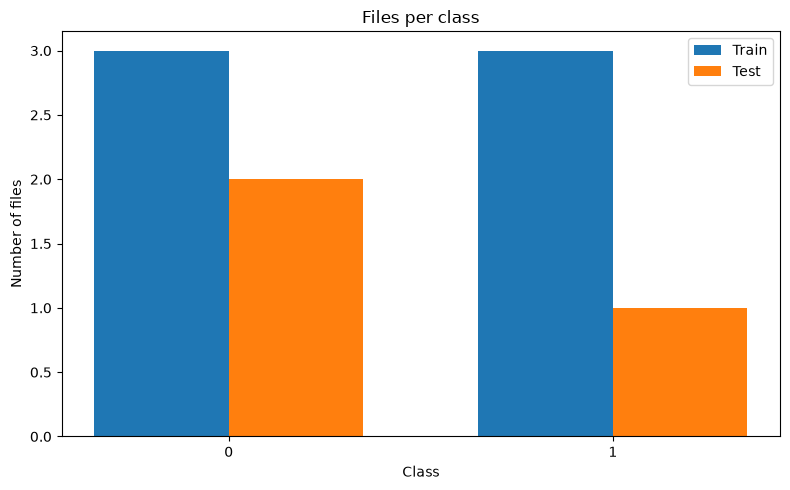

NameError: name 'frames' is not defined

In [ ]:
classes = [0, 1]
train_counts = [sum(np.array(train_labels) == c) for c in classes]
test_counts = [sum(np.array(test_labels) == c) for c in classes]

x = np.arange(len(classes))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width / 2, train_counts, width, label="Train")
ax.bar(x + width / 2, test_counts, width, label="Test")

ax.set_ylabel("Number of files")
ax.set_xlabel("Class")
ax.set_title("Files per class")
ax.set_xticks(x, classes)
ax.legend()
fig.tight_layout()
plt.show()

# Show the first, middle, and last preprocessed frames from one dataset item
#frames, label = train_path[0]  # expected shape: [T, C, H, W] 
indices = [0, len(frames) // 2, len(frames) - 1]

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(1, 3, figsize=(10, 4))
for ax, i in zip(axes, indices):
    frame = frames[i].detach().cpu() * std + mean  # undo ResNet normalization
    ax.imshow(frame.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(f"Frame {i}")
    ax.axis("off")

fig.suptitle(f"Preprocessed clip — label {label}")
fig.tight_layout()
plt.show()

__Fully Connected Neural Network__

Classifiers

In [ ]:
class BinaryVideoClassifier(nn.Module):
    def __init__(
        self,
        hidden_dim=256,
        num_lstm_layers=1,
        dropout=0.3,
    ):
        super().__init__()

        # CNN that extracts features from each frame.
        # weights=None avoids downloading pretrained weights for this test.
        backbone = resnet18(weights=None)

        # ResNet-18 normally sends its 512 features into its own classifier.
        feature_dim = backbone.fc.in_features  # 512

        # Remove ResNet's original classifier because we want its features.
        backbone.fc = nn.Identity()
        self.frame_encoder = backbone

        # Processes the sequence of frame features.
        self.temporal_model = nn.LSTM(
            input_size=feature_dim,
            hidden_size=hidden_dim,
            num_layers=num_lstm_layers,
            batch_first=True,
            dropout=dropout if num_lstm_layers > 1 else 0.0,
        )

        # Converts each video's features into one binary-classification score.
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, videos):
        """
        videos shape:
        [batch, frames, channels, height, width]
        """

        batch_size, num_frames, channels, height, width = videos.shape

        # Change:
        # [batch, frames, channels, height, width]
        # into:
        # [batch * frames, channels, height, width]
        #
        # This allows ResNet to process every frame as an image.
        frames = videos.reshape(
            batch_size * num_frames,
            channels,
            height,
            width,
        )

        # Extract 512 features from each frame.
        frame_features = self.frame_encoder(frames)

        # Restore the batch and frame dimensions:
        # [batch, frames, 512]
        frame_features = frame_features.reshape(
            batch_size,
            num_frames,
            -1,
        )

        # Process the frame sequence with the LSTM.
        # Shape: [batch, frames, hidden_dim]
        temporal_features, _ = self.temporal_model(frame_features)

        # Average the LSTM outputs across all frames.
        # Shape: [batch, hidden_dim]
        video_features = temporal_features.mean(dim=1)

        # Produce one raw score for every video.
        # Initial shape: [batch, 1]
        logits = self.classifier(video_features)

        # Remove the final size-1 dimension.
        # Final shape: [batch]
        logits = logits.squeeze(1)

        return logits

In [ ]:
model = BinaryVideoClassifier()

criterion = nn.BCEWithLogitsLoss() #Expects raw Logits - no function

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4,
)

videos = videos.to(device)                  # float: [B, T, 3, H, W]
labels = labels.to(device).float()          # float: [B]

logits = model(videos)                      # [B]
loss = criterion(logits, labels)

optimizer.zero_grad()
loss.backward()
optimizer.step()

In [ ]:
logits = model(videos) #forward method of model // calculate input, turn videos ->forward -> into logits
loss = criterion(logits, labels)

Loss and Training